In [2]:
from pathlib import Path
import json
import os
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import torch
from PIL import Image, ImageOps
from tqdm.auto import tqdm

# ===== 第二组数据集：Met chair =====
DATASET_NAME = "met_dance"

ROOT = Path.cwd()                              # Notebook 所在的文件夹：Data_analysis/

# 安全检查：Notebook 必须放在 Data_analysis 里，否则停下，避免文件乱放
if ROOT.name != "Data_analysis":
    raise RuntimeError(f"这个 Notebook 应该放在 Data_analysis 文件夹里，现在在：{ROOT}")

SHARED_DIR = ROOT / "workshop2_data"           # 两组共用的总文件夹
CHECKPOINTS_DIR = SHARED_DIR / "checkpoints"   # 模型文件：两组共用，不重复下载
DATA_DIR = SHARED_DIR / DATASET_NAME           # 这一组自己的文件夹
IMAGES_DIR = DATA_DIR / "images"
OUTPUTS_DIR = DATA_DIR / "outputs"
MASKS_DIR = OUTPUTS_DIR / "sam_masks"
DATASET_DIR = DATA_DIR                         # 别名：和第一组 Notebook 的写法兼容

for folder in [SHARED_DIR, CHECKPOINTS_DIR, DATA_DIR, IMAGES_DIR, OUTPUTS_DIR, MASKS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

if torch.cuda.is_available():
    DEVICE = "cuda"
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    DEVICE = "mps"
else:
    DEVICE = "cpu"

print("Notebook folder:", ROOT.resolve())
print("Dataset folder: ", DATA_DIR.resolve())
print("Checkpoints:    ", CHECKPOINTS_DIR.resolve())
print("Model device:   ", DEVICE)

Notebook folder: /Users/xiaoyiwen/Dfpi_Coding/Data_analysis
Dataset folder:  /Users/xiaoyiwen/Dfpi_Coding/Data_analysis/workshop2_data/met_dance
Checkpoints:     /Users/xiaoyiwen/Dfpi_Coding/Data_analysis/workshop2_data/checkpoints
Model device:    mps


/Users/xiaoyiwen/miniforge3/envs/dfpi/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
def show_image_grid(rows, image_col="local_path", title_col="title", columns=5, max_items=15):
    # Display images from a DataFrame or list of dictionaries.
    if isinstance(rows, pd.DataFrame):
        records = rows.head(max_items).to_dict("records")
    else:
        records = list(rows)[:max_items]

    if not records:
        print("No images to display.")
        return

    n = len(records)
    rows_n = int(np.ceil(n / columns))
    fig, axes = plt.subplots(rows_n, columns, figsize=(3.2 * columns, 3.4 * rows_n))
    axes = np.atleast_1d(axes).ravel()

    for ax, record in zip(axes, records):
        try:
            image = Image.open(record[image_col]).convert("RGB")
            ax.imshow(image)
        except Exception as exc:
            ax.text(0.5, 0.5, f"Could not load image\n{exc}", ha="center", va="center")
        ax.set_title(str(record.get(title_col, ""))[:55], fontsize=9)
        ax.axis("off")

    for ax in axes[n:]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()


def checkpoint_files():
    # List Hugging Face files plus Ultralytics .pt files beside the notebook.
    model_extensions = {".bin", ".safetensors", ".pt", ".pth", ".onnx"}
    files = [
        p for p in CHECKPOINTS_DIR.rglob("*")
        if p.is_file() and p.suffix.lower() in model_extensions
    ]
    root_pt_files = sorted(ROOT.glob("*.pt"))
    if not files and not root_pt_files:
        print("No checkpoints downloaded yet.")
        return
    for path in sorted(files):
        size_mb = path.stat().st_size / (1024 ** 2)
        print(f"checkpoints/{path.relative_to(CHECKPOINTS_DIR)}  ({size_mb:.1f} MB)")
    for path in root_pt_files:
        size_mb = path.stat().st_size / (1024 ** 2)
        print(f"{path.name}  ({size_mb:.1f} MB, beside notebook)")

## 1. Acquire a dataset through an API

We will use The Metropolitan Museum of Art Collection API because it:

- returns structured JSON;
- does not require an API key;
- provides object metadata and public-domain image URLs;
- demonstrates parameters, pagination and repeated requests.

Change `QUERY` to connect the example to your project: `window`, `gesture`, `harbour`, `ritual`, `map`, `war`, `play`, `movement`, etc.

The notebook uses the current paginated `/v1.1/search` endpoint. The Met search index occasionally returns a stale object ID whose detail page is missing. The download code treats this as normal, skips it quietly and continues through later result pages until it reaches the requested number of usable images.

In [4]:
# STUDENT CHOICE 1: change the word inside quotation marks.
QUERY = "dance"

# STUDENT CHOICE 2: number of images (workshop: 10-50; homework: 300)
MAX_IMAGES = 300

SEARCH_URL = "https://collectionapi.metmuseum.org/public/collection/v1.1/search"
OBJECT_URL = "https://collectionapi.metmuseum.org/public/collection/v1/objects/{object_id}"

session = requests.Session()
session.headers.update({
    "User-Agent": "UCL-DFPI-student-workshop/1.0 (educational use)"
})

# 【Claude 新增】礼貌请求 + 自动重试：
# Met 对太密集的请求会暂时返回 403 / 429 / 5xx，这时等一会儿再试（5s, 10s, 20s...），最多 5 次。
# 404（编号失效）不重试，直接返回，交给下载循环处理。
def polite_get(url, params=None, timeout=30, max_tries=5):
    wait = 5
    for attempt in range(1, max_tries + 1):
        r = session.get(url, params=params, timeout=timeout)
        if r.status_code in (403, 429, 500, 502, 503, 504):
            print(f"  Server returned {r.status_code}, waiting {wait}s (try {attempt}/{max_tries})")
            time.sleep(wait)
            wait *= 2
            continue
        return r
    return r

search_params = {
    "q": QUERY,
    "hasImages": "true",
    "offset": 0,
    "limit": 100,
}

response = polite_get(SEARCH_URL, params=search_params)
response.raise_for_status()
search_data = response.json()

object_ids = search_data.get("objectIDs") or search_data.get("objectIds") or []
print("API request:", response.url)
print("Matches reported:", search_data.get("total"))
print("IDs returned on this page:", len(object_ids))


API request: https://collectionapi.metmuseum.org/public/collection/v1.1/search?q=dance&hasImages=true&offset=0&limit=100
Matches reported: 2871
IDs returned on this page: 100


In [5]:
records = []
seen_ids = set()
stale_ids = []
unavailable_count = 0
other_failures = []

# The search index can occasionally contain an ID whose object record has been removed.
# We therefore count successful images, not attempted IDs, and request later pages if needed.
page_ids = list(object_ids)
page_limit = int(search_params["limit"])
next_offset = int(search_params["offset"]) + page_limit
reported_total = int(search_data.get("total") or len(page_ids))
max_reachable = min(reported_total, 10_000)

progress = tqdm(total=MAX_IMAGES, desc="Downloading valid public-domain images", unit="image")

while len(records) < MAX_IMAGES and page_ids:
    for object_id in page_ids:
        if len(records) >= MAX_IMAGES:
            break
        if object_id in seen_ids:
            continue
        seen_ids.add(object_id)

        try:
            object_response = polite_get(OBJECT_URL.format(object_id=object_id))   # 【改动】带重试

            # A small number of stale search results currently return 404.
            # This is an API-data issue, not an error in the student's code.
            if object_response.status_code == 404:
                stale_ids.append(object_id)
                continue

            object_response.raise_for_status()
            obj = object_response.json()

            # Keep only records with a public-domain image.
            image_url = obj.get("primaryImageSmall") or obj.get("primaryImage")
            if not obj.get("isPublicDomain") or not image_url:
                unavailable_count += 1
                continue

            suffix = Path(image_url.split("?")[0]).suffix.lower()
            if suffix not in {".jpg", ".jpeg", ".png", ".webp"}:
                suffix = ".jpg"
            local_path = IMAGES_DIR / f"met_{object_id}{suffix}"

            if not local_path.exists():
                image_response = polite_get(image_url, timeout=60)   # 【改动】带重试
                image_response.raise_for_status()
                local_path.write_bytes(image_response.content)

            # Verify that the saved file really is an image.
            with Image.open(local_path) as test_image:
                test_image.verify()

            records.append({
                "id": f"met_{object_id}",
                "object_id": object_id,
                "title": obj.get("title") or "Untitled",
                "creator": obj.get("artistDisplayName") or "Unknown",
                "date": obj.get("objectDate") or "",
                "medium": obj.get("medium") or "",
                "culture": obj.get("culture") or "",
                "classification": obj.get("classification") or "",   # 【改动】新增：作品分类
                "object_name": obj.get("objectName") or "",          # 【改动】新增：物件名称
                "source_url": obj.get("objectURL") or "",
                "image_url": image_url,
                "license": "Public domain",
                "query": QUERY,
                "local_path": str(local_path.resolve()),
            })
            progress.update(1)

        except Exception as exc:
            other_failures.append((object_id, str(exc)))
        finally:
            # Be polite to the public API.
            time.sleep(0.3)   # 【改动】0.05 → 0.3 秒，避免请求太密集被 403

    if len(records) >= MAX_IMAGES or next_offset >= max_reachable:
        break

    next_params = {**search_params, "offset": next_offset}
    # 【改动】翻页请求带重试；如果重试后还是失败，就停止翻页，但保留已下载的图片
    try:
        page_response = polite_get(SEARCH_URL, params=next_params)
        page_response.raise_for_status()
    except Exception as exc:
        print("Stopped requesting more pages:", exc)
        break
    page_data = page_response.json()
    page_ids = page_data.get("objectIDs") or page_data.get("objectIds") or []
    next_offset += page_limit

progress.close()
manifest = pd.DataFrame(records)

print(f"Dataset contains {len(manifest)} downloaded images.")
print(f"API candidates checked: {len(seen_ids)}")
if stale_ids:
    print(f"Ignored {len(stale_ids)} stale search IDs that returned 404. This is normal.")
if unavailable_count:
    print(f"Ignored {unavailable_count} records without a usable public-domain image.")
if other_failures:
    print(f"Ignored {len(other_failures)} other failed requests. First three:")
    for failed_id, reason in other_failures[:3]:
        print(f"  {failed_id}: {reason}")
if len(manifest) < MAX_IMAGES:
    print(f"Only {len(manifest)} usable images were available; requested {MAX_IMAGES}.")

manifest.head()

  Server returned 403, waiting 5s (try 1/5)
  Server returned 403, waiting 10s (try 2/5)
  Server returned 403, waiting 20s (try 3/5)


  Server returned 403, waiting 5s (try 1/5)
  Server returned 403, waiting 10s (try 2/5)


  Server returned 403, waiting 5s (try 1/5)
  Server returned 403, waiting 10s (try 2/5)


  Server returned 403, waiting 5s (try 1/5)
  Server returned 403, waiting 10s (try 2/5)


  Server returned 403, waiting 5s (try 1/5)


  Server returned 403, waiting 5s (try 1/5)


... (8 outputs left out)

  Server returned 403, waiting 5s (try 1/5)


  Server returned 403, waiting 5s (try 1/5)
  Server returned 403, waiting 10s (try 2/5)


Dataset contains 300 downloaded images.
API candidates checked: 503
Ignored 32 stale search IDs that returned 404. This is normal.
Ignored 171 records without a usable public-domain image.


,id,object_id,title,creator,date,medium,culture,classification,object_name,source_url,image_url,license,query,local_path
0,met_341421,341421,Portrait of a Man,George Dance,1796,Graphite,,Drawings,Drawing,https://www.metmuseum.org/art/collection/searc...,https://images.metmuseum.org/CRDImages/dp/web-...,Public domain,dance,/Users/xiaoyiwen/Dfpi_Coding/Data_analysis/wor...
1,met_505617,505617,Drawing of William Thomas Parke (1762-1847),George Dance,1797,Graphite on paper,British,Works on Paper,Drawing of William Thomas Parke (1762-1847),https://www.metmuseum.org/art/collection/searc...,https://images.metmuseum.org/CRDImages/mi/web-...,Public domain,dance,/Users/xiaoyiwen/Dfpi_Coding/Data_analysis/wor...
2,met_11783,11783,The Arrow Dance,Louis McClellan Potter,1907,Bronze,American,,Sculpture,https://www.metmuseum.org/art/collection/searc...,https://images.metmuseum.org/CRDImages/ad/web-...,Public domain,dance,/Users/xiaoyiwen/Dfpi_Coding/Data_analysis/wor...
3,met_79402,79402,Dance slipper,Unknown,1880s,"silk, leather, metal, vellum",Turkish,,Dance slippers,https://www.metmuseum.org/art/collection/searc...,https://images.metmuseum.org/CRDImages/ci/web-...,Public domain,dance,/Users/xiaoyiwen/Dfpi_Coding/Data_analysis/wor...
4,met_88303,88303,Dance ensemble,Unknown,20th century,Silk,Japan,Main dress,Dance ensemble,https://www.metmuseum.org/art/collection/searc...,https://images.metmuseum.org/CRDImages/as/web-...,Public domain,dance,/Users/xiaoyiwen/Dfpi_Coding/Data_analysis/wor...


Saved: /Users/xiaoyiwen/Dfpi_Coding/Data_analysis/workshop2_data/met_dance/manifest.csv
Rows in manifest: 300

Classification:
classification
Prints                                       222
Drawings                                      11
Paintings                                     11
                                               9
Wood-Sculpture                                 4
Idiophone-Shaken-rattle                        4
Terracottas                                    4
Membranophone-single-headed / goblet drum      3
Main dress                                     2
Wood-Implements                                2
Name: count, dtype: int64

Object name:
object_name
Print              215
Drawing             10
Painting            10
Dance ensemble       3
Woodblock print      3
Dance paddle         2
Paddle               2
Figure               2
Inrō                 2
T'arija              2
Name: count, dtype: int64


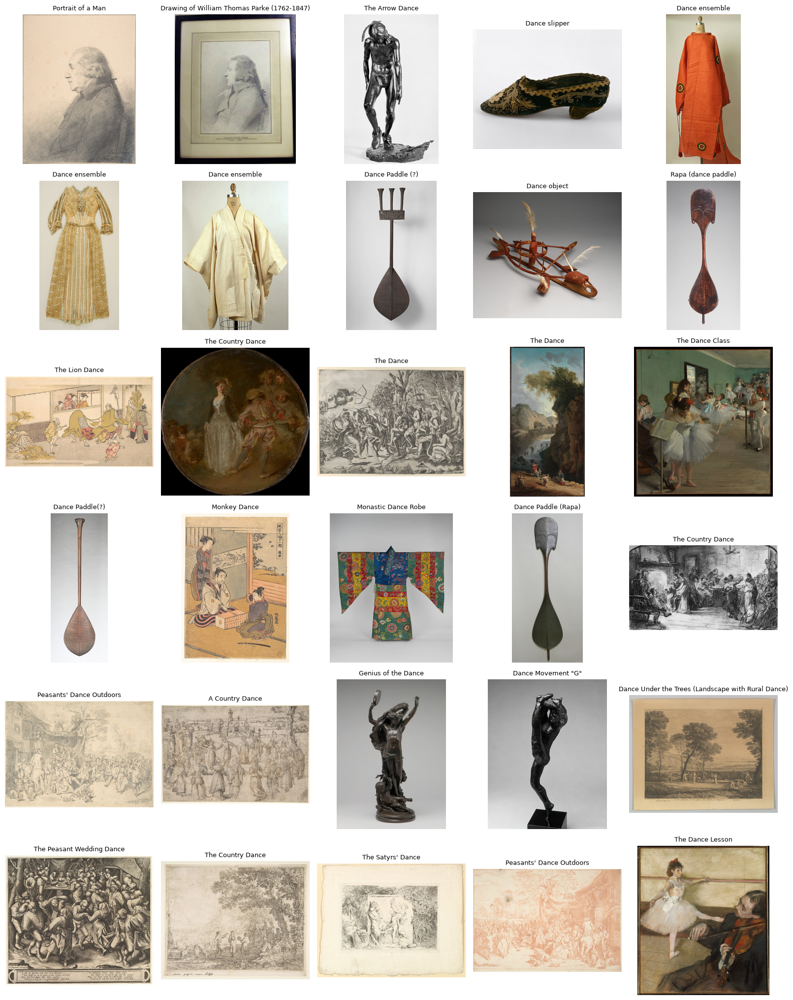

In [6]:
manifest_path = DATA_DIR / "manifest.csv"
manifest.to_csv(manifest_path, index=False, encoding="utf-8")
print("Saved:", manifest_path.resolve())
print("Rows in manifest:", len(manifest))
print()
print("Classification:")                                    # 【改动】新增检查
print(manifest["classification"].value_counts().head(10))
print()
print("Object name:")
print(manifest["object_name"].value_counts().head(10))
show_image_grid(manifest, columns=5, max_items=30)


## 2. CLIP — semantic similarity

CLIP maps images and text into the same embedding space. We can therefore ask:

- Which image is most similar to a sentence?
- Which images are visually/semantically close to a selected image?
- How can the dataset be arranged in two dimensions?

### Explicit checkpoint download

The next cell downloads the complete PyTorch CLIP checkpoint and processor configuration from Hugging Face into:

`workshop2_data/checkpoints/clip-vit-base-patch32/`

Re-running the cell uses the local cache and does not download unchanged files again.

In [7]:
from huggingface_hub import snapshot_download

CLIP_MODEL_ID = "openai/clip-vit-base-patch32"
CLIP_CHECKPOINT_DIR = CHECKPOINTS_DIR / "clip-vit-base-patch32"

snapshot_download(
    repo_id=CLIP_MODEL_ID,
    local_dir=CLIP_CHECKPOINT_DIR,
    ignore_patterns=[
        "*.msgpack", "*.h5", "*.onnx", "*.tflite",
        "flax_model.*", "tf_model.*"
    ],
)

print("CLIP checkpoint downloaded/cached at:")
print(CLIP_CHECKPOINT_DIR.resolve())
checkpoint_files()

Fetching 10 files: 100%|█████████████████████| 10/10 [00:00<00:00, 1039.27it/s]

CLIP checkpoint downloaded/cached at:
/Users/xiaoyiwen/Dfpi_Coding/Data_analysis/workshop2_data/checkpoints/clip-vit-base-patch32
checkpoints/clip-vit-base-patch32/pytorch_model.bin  (577.2 MB)
sam2.1_b.pt  (154.4 MB, beside notebook)
yolo26n.pt  (5.3 MB, beside notebook)
yoloe-26s-seg.pt  (29.6 MB, beside notebook)


In [8]:
from transformers import CLIPModel, CLIPProcessor

clip_model = CLIPModel.from_pretrained(CLIP_CHECKPOINT_DIR).to(DEVICE).eval()
clip_processor = CLIPProcessor.from_pretrained(CLIP_CHECKPOINT_DIR)

print("Loaded:", CLIP_MODEL_ID)
print("Device:", DEVICE)

W1027 04:03:17.481000 36818 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.
Loading weights: 100%|████████████████████| 398/398 [00:00<00:00, 63579.11it/s]


Loaded: openai/clip-vit-base-patch32
Device: mps


In [9]:
if manifest.empty:
    raise ValueError("The manifest is empty. Run the API section or add local images first.")

image_paths = manifest["local_path"].tolist()
batch_size = 16 if DEVICE == "cuda" else 8
feature_batches = []

for start in tqdm(range(0, len(image_paths), batch_size), desc="CLIP image embeddings"):
    batch_paths = image_paths[start:start + batch_size]
    batch_images = [Image.open(path).convert("RGB") for path in batch_paths]
    inputs = clip_processor(images=batch_images, return_tensors="pt")
    inputs = {key: value.to(DEVICE) for key, value in inputs.items()}

    with torch.inference_mode():
        feature_output = clip_model.get_image_features(**inputs)
        # Transformers 5 returns a structured output; older versions return a tensor.
        features = (
            feature_output.pooler_output
            if hasattr(feature_output, "pooler_output")
            else feature_output
        )
        features = features / features.norm(dim=-1, keepdim=True)

    feature_batches.append(features.cpu().float().numpy())

image_embeddings = np.vstack(feature_batches)
embeddings_path = OUTPUTS_DIR / "clip_image_embeddings.npy"
np.save(embeddings_path, image_embeddings)

print("Embedding matrix:", image_embeddings.shape)
print("Saved:", embeddings_path.resolve())

CLIP image embeddings: 100%|███████████████████| 38/38 [00:02<00:00, 14.76it/s]


Embedding matrix: (300, 512)
Saved: /Users/xiaoyiwen/Dfpi_Coding/Data_analysis/workshop2_data/met_dance/outputs/clip_image_embeddings.npy


,title,creator,date,clip_similarity
234,"An Actor in the Fox Dance from the Drama, ""The...",Ippitsusai Bunchō,1723–1792,0.217983
50,The Dance of the Scarves,Ishikawa Toyonobu,,0.214829
16,Monkey Dance,Isoda Koryūsai,ca. 1760,0.212956
186,A Fox Dance from the Drama The Thousand Cherry...,Ippitsusai Bunchō,,0.212636
199,"Flower Dance, from National Dances (N225, Type...",Kinney Brothers Tobacco Company,1889,0.212577
105,"Representation of the Dance-Play ""Dōjōji""",Utagawa Toyokuni I,,0.212187
98,"Bridal pair, from ""Dance of Death""",Wenceslaus Hollar,[1651] late 18th century printing,0.212149
48,Scene from Noh Dance,Totoya Hokkei,ca. 1820,0.211496
239,The Dance of the Beach Maidens from the series...,Torii Kiyonaga,ca. 1770,0.211100
285,Costume for Bugaku Court Dance\r\nFrom the Spr...,Ryūryūkyo Shinsai,probably 1818 (Year of the Tiger),0.210198


) missing from font(s) DejaVu Sans.hdr0h0000gn/T/ipykernel_36818/135577360.py:28: UserWarning: Glyph 13 (
  plt.tight_layout()
) missing from font(s) DejaVu Sans.pi/lib/python3.11/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 13 (
  fig.canvas.print_figure(bytes_io, **kw)


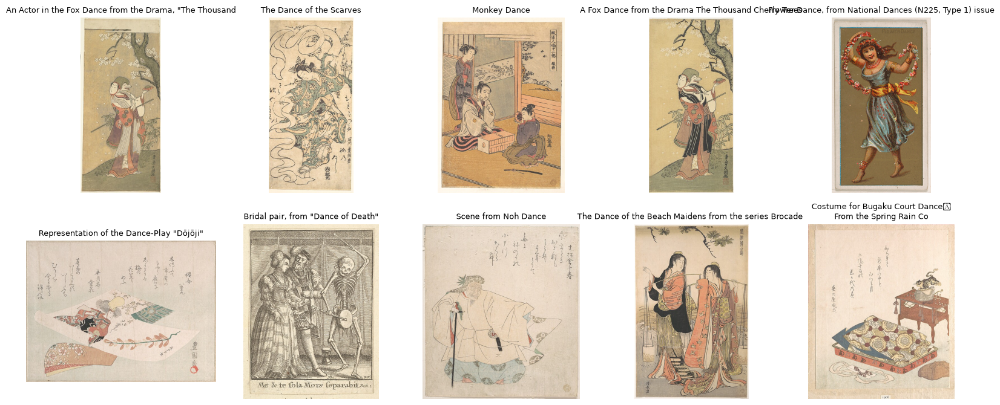

,title,creator,date,clip_similarity
69,"Old Woman, from ""Dance of Death""",Wenceslaus Hollar,[1651] late 18th century printing,0.211047
286,Shak-Shak,Atorios People,19th century,0.210194
98,"Bridal pair, from ""Dance of Death""",Wenceslaus Hollar,[1651] late 18th century printing,0.209123
258,Udäkki,Unknown,late 19th Century,0.208183
2,The Arrow Dance,Louis McClellan Potter,1907,0.205124
171,"War Dance, from National Dances (N225, Type 1)...",Kinney Brothers Tobacco Company,1889,0.203658
103,"Old Man, from ""Dance of Death""",Wenceslaus Hollar,[1651] late 18th century printing,0.202708
114,"The Abbot, from ""The Dance of Death""",Hans Holbein the Younger,"ca. 1526, published 1538",0.200374
16,Monkey Dance,Isoda Koryūsai,ca. 1760,0.200202
48,Scene from Noh Dance,Totoya Hokkei,ca. 1820,0.200043


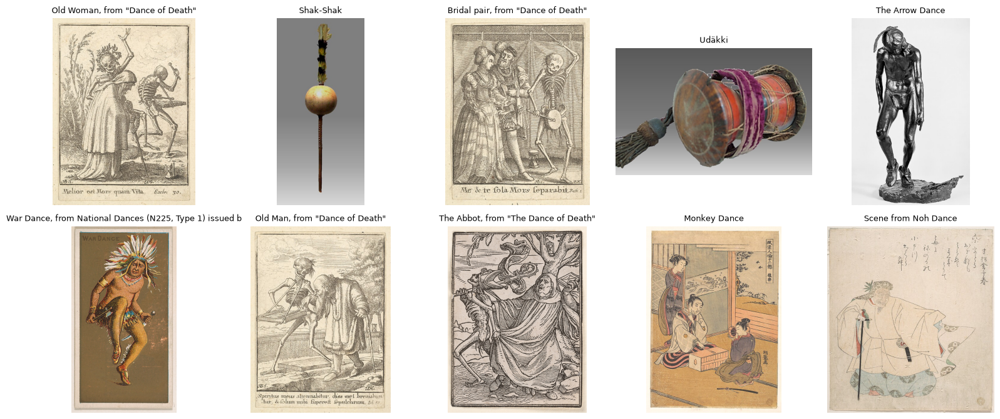

In [10]:
def search_images_with_text(query, top_k=8):
    text_inputs = clip_processor(text=[query], return_tensors="pt", padding=True)
    text_inputs = {key: value.to(DEVICE) for key, value in text_inputs.items()}

    with torch.inference_mode():
        text_feature_output = clip_model.get_text_features(**text_inputs)
        # Use the projected tensor from either the new or older API.
        text_features = (
            text_feature_output.pooler_output
            if hasattr(text_feature_output, "pooler_output")
            else text_feature_output
        )
        text_features = text_features / text_features.norm(dim=-1, keepdim=True)

    similarities = image_embeddings @ text_features.cpu().float().numpy()[0]
    order = np.argsort(similarities)[::-1][:top_k]
    results = manifest.iloc[order].copy()
    results["clip_similarity"] = similarities[order]
    return results


# STUDENT CHOICE 4: describe something you want to find in plain language.
TEXT_QUERY = "happy"
text_results = search_images_with_text(TEXT_QUERY, top_k=10)
display(text_results[["title", "creator", "date", "clip_similarity"]])
show_image_grid(text_results, columns=5, max_items=10)

TEXT_QUERY2 = "sad"
text_results2 = search_images_with_text(TEXT_QUERY2, top_k=10)
display(text_results2[["title", "creator", "date", "clip_similarity"]])
show_image_grid(text_results2, columns=5, max_items=10)

Selected image: The Lion Dance


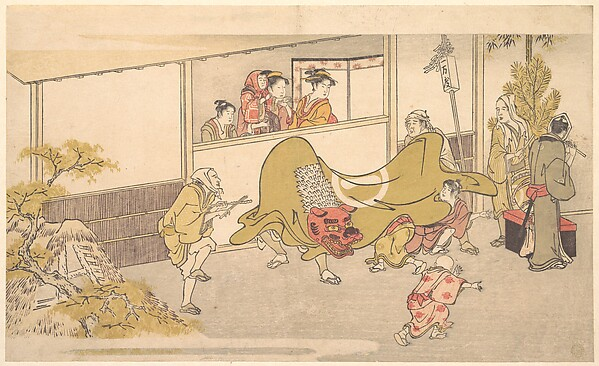

,title,creator,date,clip_similarity
144,Furuichi Dance (No. 2 of a Set of Four),Yashima Gakutei,19th century,0.861742
226,Courtier Playing a Flute to Accompany a Bugaku...,Kubo Shunman,probably 1810,0.857209
269,Interior Scene in the Yoshiwara,Hishikawa Moronobu,ca. 1680,0.853144
105,"Representation of the Dance-Play ""Dōjōji""",Utagawa Toyokuni I,,0.845920
16,Monkey Dance,Isoda Koryūsai,ca. 1760,0.840592
87,"The Ninth-Month Kabuki Dance ""Kikujido""",Katsushika Hokusai,ca. 1796,0.838115
164,Furuichi Dance (No. 3 of a Set of Four),Yashima Gakutei,19th century,0.836544
167,"Two Actors in a Yari-odori, i.e. Spear Dance",Okumura Masanobu,1710–13,0.832645
88,Bugaku Imperial Court Dance,Unknown,17th century,0.832544
165,Furuichi Dance (No. 4 of a Set of Four),Yashima Gakutei,19th century,0.829754


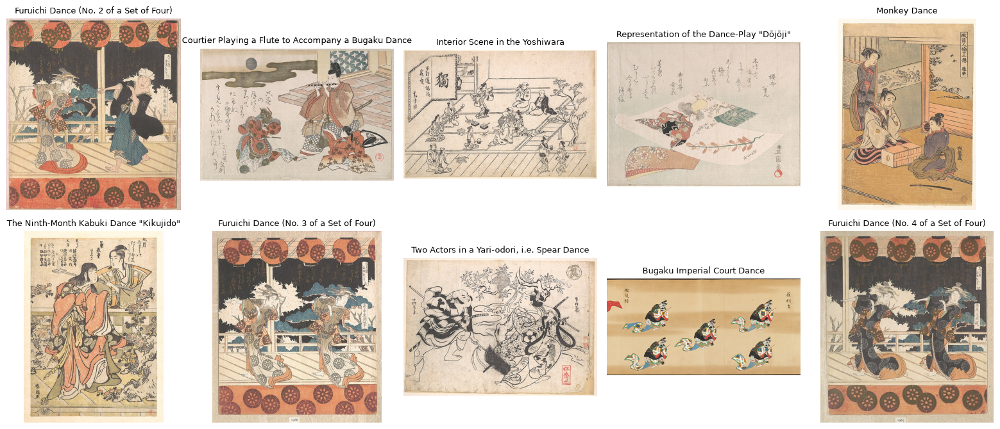

In [11]:
def nearest_images(image_index, top_k=8):
    similarities = image_embeddings @ image_embeddings[image_index]
    order = np.argsort(similarities)[::-1]
    order = order[order != image_index][:top_k]
    results = manifest.iloc[order].copy()
    results["clip_similarity"] = similarities[order]
    return results


# STUDENT CHOICE 5: choose a row number from 0 to len(manifest) - 1.
SELECTED_IMAGE_INDEX = 10 # replace with any row
print("Selected image:", manifest.iloc[SELECTED_IMAGE_INDEX]["title"])
display(Image.open(manifest.iloc[SELECTED_IMAGE_INDEX]["local_path"]).convert("RGB"))

neighbour_results = nearest_images(SELECTED_IMAGE_INDEX, top_k=10)
display(neighbour_results[["title", "creator", "date", "clip_similarity"]])
show_image_grid(neighbour_results, columns=5, max_items=10)

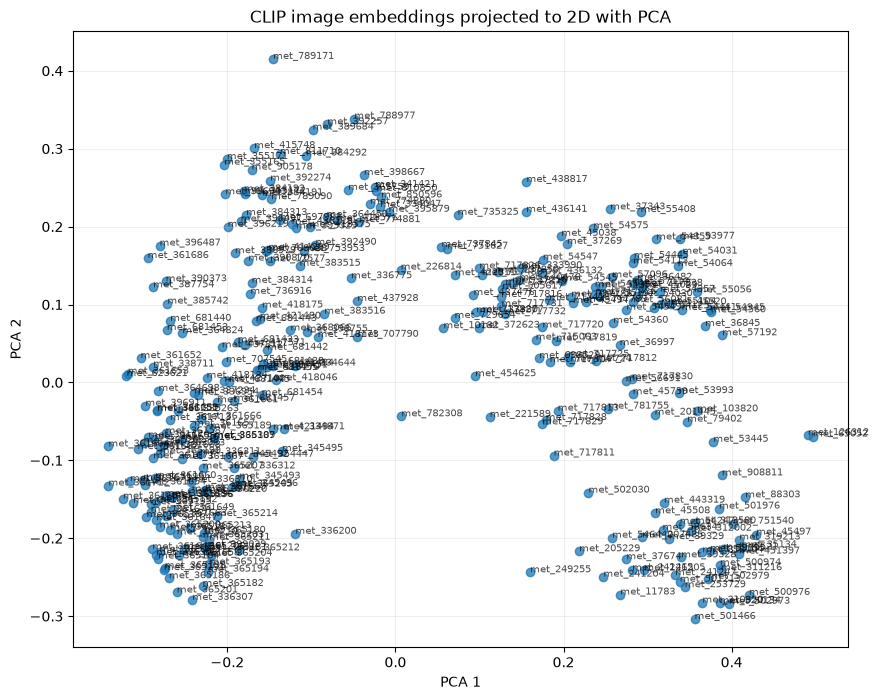

In [12]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
embedding_2d = pca.fit_transform(image_embeddings)

manifest["clip_x"] = embedding_2d[:, 0]
manifest["clip_y"] = embedding_2d[:, 1]

plt.figure(figsize=(10, 8))
plt.scatter(manifest["clip_x"], manifest["clip_y"], alpha=0.75)
for _, row in manifest.iterrows():
    plt.annotate(str(row["id"]), (row["clip_x"], row["clip_y"]), fontsize=7, alpha=0.7)
plt.title("CLIP image embeddings projected to 2D with PCA")
plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.grid(alpha=0.2)
plt.show()

## 3. YOLO - audit a closed vocabulary

YOLO26 is trained to recognise a fixed set of everyday COCO categories. It returns bounding boxes, class IDs and confidence scores, which we convert into `detections.csv`.

For architectural ornaments, drawings and artworks, many predictions may be absent or wrong. **That failure is an analytical result:** it tells us what the model's training vocabulary cannot describe. A larger YOLO26 checkpoint may improve accuracy within the same categories, but it does not create a new vocabulary.

### Explicit checkpoint download

Ultralytics downloads official checkpoints the first time a model name is loaded. We load the lightweight `yolo26n.pt` checkpoint for this audit. **SAM will not depend on these YOLO boxes.**

In [13]:
from ultralytics import YOLO, settings

settings.update({
    "weights_dir": str(CHECKPOINTS_DIR.resolve()),
    "runs_dir": str((OUTPUTS_DIR / "runs").resolve()),
})

YOLO_CHECKPOINT = "yolo26n.pt"
yolo_model = YOLO(YOLO_CHECKPOINT)  # downloads the checkpoint if it is absent

print("YOLO checkpoint ready:", YOLO_CHECKPOINT)
print("Ultralytics weights directory:", settings["weights_dir"])
checkpoint_files()

YOLO checkpoint ready: yolo26n.pt
Ultralytics weights directory: /Users/xiaoyiwen/Dfpi_Coding/Data_analysis/workshop2_data/checkpoints
checkpoints/clip-vit-base-patch32/pytorch_model.bin  (577.2 MB)
sam2.1_b.pt  (154.4 MB, beside notebook)
yolo26n.pt  (5.3 MB, beside notebook)
yoloe-26s-seg.pt  (29.6 MB, beside notebook)


In [14]:
path_to_id = {
    str(Path(row.local_path).resolve()).lower(): row.id
    for row in manifest.itertuples()
}

detection_rows = []
prediction_stream = yolo_model.predict(
    source=manifest["local_path"].tolist(),
    stream=True,
    conf=0.25,
    imgsz=640,
    device=DEVICE,
    verbose=False,
)

for result in tqdm(prediction_stream, total=len(manifest), desc="YOLO detections"):
    resolved_path = str(Path(result.path).resolve()).lower()
    image_id = path_to_id.get(resolved_path, Path(result.path).stem)

    if result.boxes is None or len(result.boxes) == 0:
        continue

    boxes_xyxy = result.boxes.xyxy.cpu().numpy()
    confidences = result.boxes.conf.cpu().numpy()
    class_ids = result.boxes.cls.cpu().numpy().astype(int)

    for box, confidence, class_id in zip(boxes_xyxy, confidences, class_ids):
        x1, y1, x2, y2 = box.tolist()
        detection_rows.append({
            "image_id": image_id,
            "class_id": class_id,
            "class_name": result.names[class_id],
            "confidence": float(confidence),
            "x1": float(x1),
            "y1": float(y1),
            "x2": float(x2),
            "y2": float(y2),
            "width": float(x2 - x1),
            "height": float(y2 - y1),
        })

detections = pd.DataFrame(detection_rows)
detections_path = OUTPUTS_DIR / "detections.csv"
detections.to_csv(detections_path, index=False)

print(f"Detected {len(detections)} objects across {len(manifest)} images.")
print("Saved:", detections_path.resolve())
detections.head(10)

YOLO detections: 100%|███████████████████████| 300/300 [00:06<00:00, 44.18it/s]

Detected 556 objects across 300 images.
Saved: /Users/xiaoyiwen/Dfpi_Coding/Data_analysis/workshop2_data/met_dance/outputs/detections.csv


,image_id,class_id,class_name,confidence,x1,y1,x2,y2,width,height
0,met_341421,0,person,0.803007,0.000000,131.926422,469.083191,618.320801,469.083191,486.394379
1,met_505617,0,person,0.847161,164.962479,168.599213,394.184753,499.271271,229.222275,330.672058
2,met_11783,0,person,0.868859,74.093842,24.840956,243.656082,568.702393,169.562241,543.861437
3,met_126312,0,person,0.585837,1.424844,17.279564,440.662933,619.718140,439.238090,602.438576
4,met_312002,40,wine glass,0.256648,90.251656,11.509959,220.221329,593.371277,129.969673,581.861318
5,met_437928,45,bowl,0.376534,8.597145,2.395731,595.213867,566.713013,586.616722,564.317281
6,met_437928,0,person,0.271575,306.436371,85.137337,547.824707,533.516113,241.388336,448.378777
7,met_437476,0,person,0.685260,86.677017,479.780853,117.435486,528.626831,30.758469,48.845978
8,met_437476,0,person,0.606481,199.462753,509.571350,228.747650,555.157043,29.284897,45.585693
9,met_437476,0,person,0.487821,116.567375,506.506531,131.971542,542.524414,15.404167,36.017883


Selected image: The Lion Dance


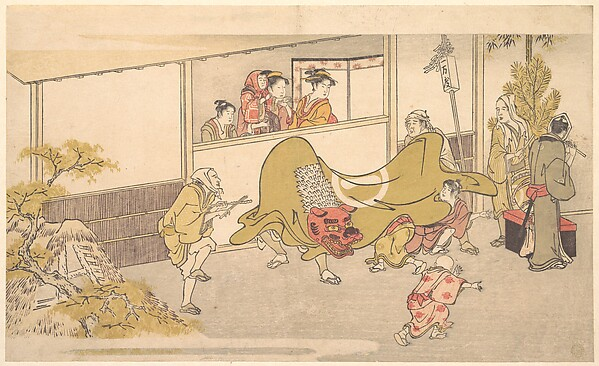

In [15]:
# STUDENT CHOICE 6: choose which image YOLO should demonstrate.
# The default is the same cookbook cover used later for the YOLOE comparison.
DEMO_IMAGE_INDEX = min(10, len(manifest) - 1)
demo_image_path = manifest.iloc[DEMO_IMAGE_INDEX]["local_path"]
print("Selected image:", manifest.iloc[DEMO_IMAGE_INDEX]["title"])
demo_result = yolo_model.predict(
    demo_image_path,
    conf=0.25,
    imgsz=640,
    device=DEVICE,
    verbose=False,
)[0]

# Ultralytics plotting returns BGR; reverse channels for PIL/RGB display.
annotated_rgb = demo_result.plot()[..., ::-1]
display(Image.fromarray(annotated_rgb))

In [16]:
if detections.empty:
    detection_counts = pd.DataFrame(index=manifest["id"])
else:
    detection_counts = (
        detections.groupby(["image_id", "class_name"])
        .size()
        .unstack(fill_value=0)
        .add_prefix("detected_")
    )

manifest_enriched = manifest.set_index("id").join(detection_counts).reset_index()
manifest_enriched.to_csv(OUTPUTS_DIR / "manifest_enriched.csv", index=False)

detected_image_count = detections["image_id"].nunique() if not detections.empty else 0
coverage = detected_image_count / len(manifest) if len(manifest) else 0
print(f"YOLO found at least one known COCO object in {detected_image_count}/{len(manifest)} images ({coverage:.1%}).")
print("Inspect the labels visually. A high confidence score does not make an irrelevant label correct.")
display(detection_counts.sum().sort_values(ascending=False).head(15).to_frame("total"))
manifest_enriched.head()

YOLO found at least one known COCO object in 182/300 images (60.7%).
Inspect the labels visually. A high confidence score does not make an irrelevant label correct.


,total
class_name,
detected_person,402
detected_horse,36
detected_clock,28
detected_vase,16
detected_kite,15
detected_zebra,9
detected_book,8
detected_bed,4
detected_umbrella,4


,id,object_id,title,creator,date,medium,culture,classification,object_name,source_url,...,detected_sheep,detected_spoon,detected_stop sign,detected_suitcase,detected_teddy bear,detected_tie,detected_umbrella,detected_vase,detected_wine glass,detected_zebra
0,met_341421,341421,Portrait of a Man,George Dance,1796,Graphite,,Drawings,Drawing,https://www.metmuseum.org/art/collection/searc...,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,met_505617,505617,Drawing of William Thomas Parke (1762-1847),George Dance,1797,Graphite on paper,British,Works on Paper,Drawing of William Thomas Parke (1762-1847),https://www.metmuseum.org/art/collection/searc...,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,met_11783,11783,The Arrow Dance,Louis McClellan Potter,1907,Bronze,American,,Sculpture,https://www.metmuseum.org/art/collection/searc...,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,met_79402,79402,Dance slipper,Unknown,1880s,"silk, leather, metal, vellum",Turkish,,Dance slippers,https://www.metmuseum.org/art/collection/searc...,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,met_88303,88303,Dance ensemble,Unknown,20th century,Silk,Japan,Main dress,Dance ensemble,https://www.metmuseum.org/art/collection/searc...,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 4. SAM 2.1 - promptable segmentation

SAM answers **which pixels belong to the region I indicate?** It does not need to know the object's name. This makes it much more appropriate for ornament, material, drawings and unfamiliar architectural forms.

Unlike the earlier version of this notebook, SAM is **independent of YOLO**. You will try three modes: a point prompt, a manual box prompt and optional segment-everything mode.

The default `sam2.1_b.pt` checkpoint prioritises segmentation quality. On a slow computer, change it to `sam2.1_t.pt`. A larger checkpoint cannot decide what you mean by itself: the prompt still matters.

### SAM mode A - select a region with one positive point

In [17]:
from ultralytics import SAM

# STUDENT CHOICE 7: use sam2.1_b.pt for quality or sam2.1_t.pt for speed.
SAM_CHECKPOINT = "sam2.1_b.pt"
sam_model = SAM(SAM_CHECKPOINT)  # downloads the checkpoint if it is absent

print("SAM checkpoint ready:", SAM_CHECKPOINT)
checkpoint_files()

SAM checkpoint ready: sam2.1_b.pt
checkpoints/clip-vit-base-patch32/pytorch_model.bin  (577.2 MB)
sam2.1_b.pt  (154.4 MB, beside notebook)
yolo26n.pt  (5.3 MB, beside notebook)
yoloe-26s-seg.pt  (29.6 MB, beside notebook)


Positive point [x, y]: [299, 183]


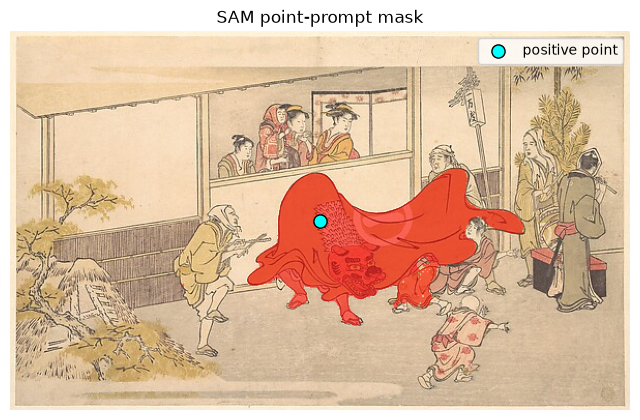

Mask covers 8.9% of the image.
Saved: /Users/xiaoyiwen/Dfpi_Coding/Data_analysis/workshop2_data/met_dance/outputs/sam_masks/met_37269_point_mask.png


In [18]:
# A point prompt: tell SAM which visible region you mean.
# STUDENT CHOICE 8: choose the SAM image independently, so this works when YOLO is skipped.
SAM_IMAGE_INDEX = 10
# Fractions are easier than pixel coordinates: 0 is left/top and 1 is right/bottom.
# STUDENT CHOICE 9: move the point by changing these two numbers between 0 and 1.
POINT_X_FRACTION = 0.50
POINT_Y_FRACTION = 0.50

demo_image_path = manifest.iloc[SAM_IMAGE_INDEX]["local_path"]
with Image.open(demo_image_path) as image:
    image_width, image_height = image.size
    demo_image_rgb = image.convert("RGB")

point_prompt = [
    int(image_width * POINT_X_FRACTION),
    int(image_height * POINT_Y_FRACTION),
]
print("Positive point [x, y]:", point_prompt)

sam_point_result = sam_model(
    demo_image_path,
    points=[point_prompt],
    labels=[1],                 # 1 means include this region
    imgsz=1024,
    device=DEVICE,
    verbose=False,
)[0]

if sam_point_result.masks is None:
    print("No mask was returned. Move the point onto a clearer region and rerun this cell.")
else:
    point_mask = sam_point_result.masks.data[0].cpu().numpy() > 0.5
    point_mask_path = MASKS_DIR / f"{manifest.iloc[SAM_IMAGE_INDEX]['id']}_point_mask.png"
    Image.fromarray((point_mask * 255).astype(np.uint8)).save(point_mask_path)

    plt.figure(figsize=(8, 8))
    plt.imshow(demo_image_rgb)
    plt.imshow(np.ma.masked_where(~point_mask, point_mask), cmap="autumn", alpha=0.55)
    plt.scatter(*point_prompt, s=90, c="cyan", edgecolors="black", label="positive point")
    plt.legend()
    plt.title("SAM point-prompt mask")
    plt.axis("off")
    plt.show()

    print(f"Mask covers {point_mask.mean():.1%} of the image.")
    print("Saved:", point_mask_path.resolve())

### SAM mode B - draw an approximate box

A box tells SAM to find the coherent region inside a rectangle. The four fractions below mean **left, top, right, bottom**. They remain valid when image sizes change.

Box [left, top, right, bottom]: [29, 18, 569, 347]


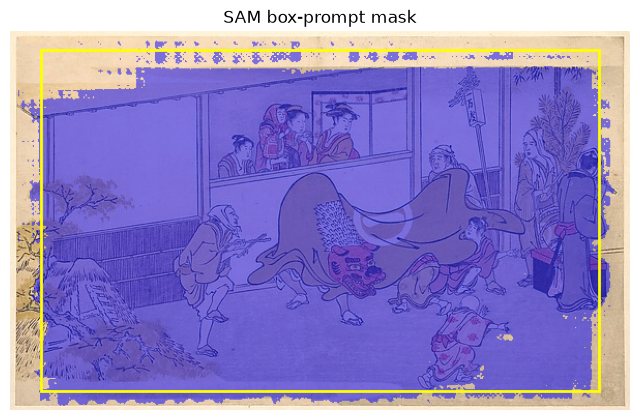

Mask covers 78.9% of the image.
Saved: /Users/xiaoyiwen/Dfpi_Coding/Data_analysis/workshop2_data/met_dance/outputs/sam_masks/met_37269_box_mask.png


In [19]:
# STUDENT CHOICE 10: adjust the box edges between 0 and 1.
BOX_LEFT = 0.05
BOX_TOP = 0.05
BOX_RIGHT = 0.95
BOX_BOTTOM = 0.95

box_prompt = [
    int(image_width * BOX_LEFT),
    int(image_height * BOX_TOP),
    int(image_width * BOX_RIGHT),
    int(image_height * BOX_BOTTOM),
]
print("Box [left, top, right, bottom]:", box_prompt)

sam_box_result = sam_model(
    demo_image_path,
    bboxes=box_prompt,
    imgsz=1024,
    device=DEVICE,
    verbose=False,
)[0]

if sam_box_result.masks is None:
    print("No mask was returned. Adjust the box and rerun this cell.")
else:
    box_mask = sam_box_result.masks.data[0].cpu().numpy() > 0.5
    box_mask_path = MASKS_DIR / f"{manifest.iloc[SAM_IMAGE_INDEX]['id']}_box_mask.png"
    Image.fromarray((box_mask * 255).astype(np.uint8)).save(box_mask_path)

    plt.figure(figsize=(8, 8))
    plt.imshow(demo_image_rgb)
    plt.imshow(np.ma.masked_where(~box_mask, box_mask), cmap="winter", alpha=0.5)
    rectangle = plt.Rectangle(
        (box_prompt[0], box_prompt[1]),
        box_prompt[2] - box_prompt[0],
        box_prompt[3] - box_prompt[1],
        fill=False, edgecolor="yellow", linewidth=2,
    )
    plt.gca().add_patch(rectangle)
    plt.title("SAM box-prompt mask")
    plt.axis("off")
    plt.show()

    print(f"Mask covers {box_mask.mean():.1%} of the image.")
    print("Saved:", box_mask_path.resolve())

### SAM mode C - segment everything (optional)

With no prompt, SAM proposes many overlapping regions. This is useful for discovering repeated parts, openings and materials, but it is slower and does not attach names. On a CPU it may take around a minute for one image.

Set `RUN_SEGMENT_EVERYTHING = False   # 【改动】可选部分，关闭` only when you want to run it. The cell filters extremely tiny masks and saves the remaining masks plus a summary table.

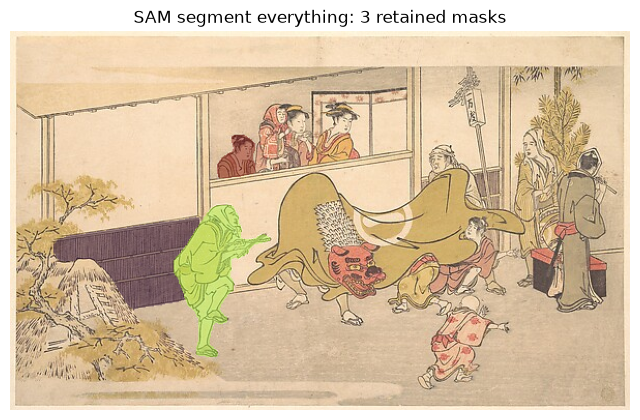

SAM proposed 3 masks; retained and saved 3.
Summary: /Users/xiaoyiwen/Dfpi_Coding/Data_analysis/workshop2_data/met_dance/outputs/sam_mask_summary.csv


,image_id,mask_index,pixel_area,area_fraction,mask_path
0,met_37269,0,6837,0.031186,/Users/xiaoyiwen/Dfpi_Coding/Data_analysis/wor...
1,met_37269,1,5709,0.026041,/Users/xiaoyiwen/Dfpi_Coding/Data_analysis/wor...
2,met_37269,2,1126,0.005136,/Users/xiaoyiwen/Dfpi_Coding/Data_analysis/wor...


In [20]:
# STUDENT CHOICE 11: change to True to run the slower automatic mode.
RUN_SEGMENT_EVERYTHING = True
MIN_MASK_AREA_FRACTION = 0.001   # ignore masks smaller than 0.1% of the image
MAX_MASKS_TO_KEEP = 40

sam_mask_summary = pd.DataFrame()

if not RUN_SEGMENT_EVERYTHING:
    print("Skipped. Change RUN_SEGMENT_EVERYTHING to True when you want to run this mode.")
else:
    sam_everything_result = sam_model(
        demo_image_path,
        imgsz=1024,
        device=DEVICE,
        verbose=False,
    )[0]

    if sam_everything_result.masks is None:
        print("No automatic masks were returned for this image.")
    else:
        all_masks = sam_everything_result.masks.data.cpu().numpy() > 0.5
        areas = all_masks.sum(axis=(1, 2))
        area_fractions = areas / (all_masks.shape[1] * all_masks.shape[2])
        keep = np.where(area_fractions >= MIN_MASK_AREA_FRACTION)[0]
        keep = keep[np.argsort(areas[keep])[::-1]][:MAX_MASKS_TO_KEEP]

        overlay = np.zeros((*all_masks.shape[1:], 4), dtype=float)
        colours = plt.cm.turbo(np.linspace(0, 1, max(len(keep), 1)))
        summary_rows = []

        for colour, mask_index in zip(colours, keep):
            mask = all_masks[mask_index]
            overlay[mask] = [colour[0], colour[1], colour[2], 0.45]
            mask_path = MASKS_DIR / f"{manifest.iloc[SAM_IMAGE_INDEX]['id']}_auto_{mask_index:03d}.png"
            Image.fromarray((mask * 255).astype(np.uint8)).save(mask_path)
            summary_rows.append({
                "image_id": manifest.iloc[SAM_IMAGE_INDEX]["id"],
                "mask_index": int(mask_index),
                "pixel_area": int(areas[mask_index]),
                "area_fraction": float(area_fractions[mask_index]),
                "mask_path": str(mask_path.resolve()),
            })

        sam_mask_summary = pd.DataFrame(summary_rows)
        sam_summary_path = OUTPUTS_DIR / "sam_mask_summary.csv"
        sam_mask_summary.to_csv(sam_summary_path, index=False)

        plt.figure(figsize=(8, 8))
        plt.imshow(demo_image_rgb)
        plt.imshow(overlay)
        plt.title(f"SAM segment everything: {len(keep)} retained masks")
        plt.axis("off")
        plt.show()

        print(f"SAM proposed {len(all_masks)} masks; retained and saved {len(keep)}.")
        print("Summary:", sam_summary_path.resolve())
        display(sam_mask_summary.head(10))

## 5. YOLOE - open-vocabulary detection and segmentation

Ordinary YOLO asks: *is this one of my fixed COCO categories?* That is why a cookbook cover may be reduced to labels such as `bowl` or `orange`. YOLOE instead accepts categories that **you name** and returns both boxes and masks. This makes it more useful for project-specific visual research.

Run the next cell while connected to the internet. On each student's computer, the first run downloads `yoloe-26s-seg.pt`, installs the text-encoder component and downloads an additional text encoder of about 254 MB; later runs reuse the cached files. The first run can therefore take several minutes. Use short, concrete visual nouns such as `face`, `food`, `flower` or `building`; abstract ideas are harder. Outputs are still propositions, not ground truth.

Selected image: Peasants' Dance Outdoors
Prompts: ['dancer', 'musician', 'musical instrument', 'mask', 'dress', 'drum', 'fan', 'costume', 'stage', 'audience']


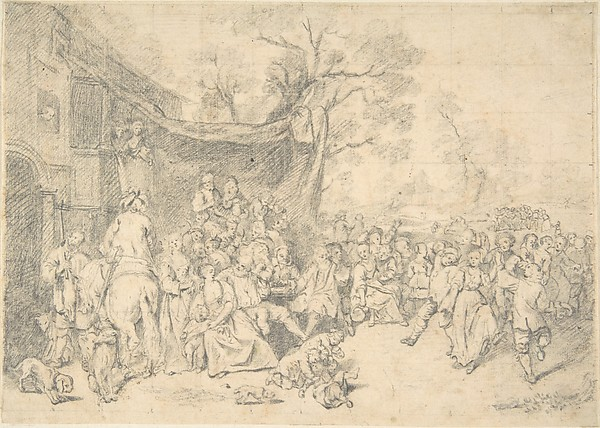

/Users/xiaoyiwen/miniforge3/envs/dfpi/lib/python3.11/site-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


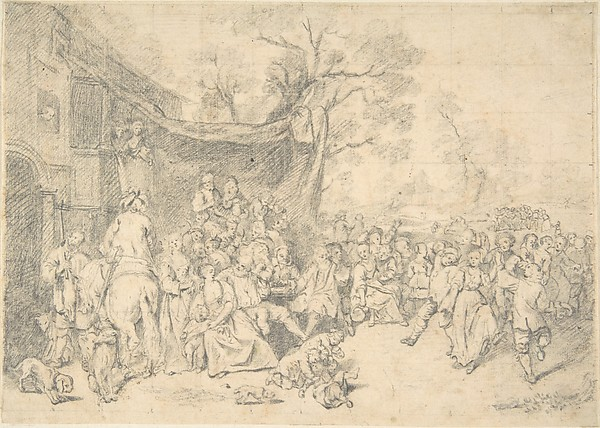

,image_id,title,class_name,confidence,x1,y1,x2,y2


Saved detection table: /Users/xiaoyiwen/Dfpi_Coding/Data_analysis/workshop2_data/met_dance/outputs/yoloe_detections.csv
No masks were found. Try simpler nouns, a different image, or conf=0.10.


In [21]:
# STUDENT CHOICE 12: choose an image row from 0 to len(manifest) - 1.
YOLOE_IMAGE_INDEX = min(20, len(manifest) - 1)

# STUDENT CHOICE 13: replace these with 3-10 concrete things relevant to your project.
# Everyday visual nouns usually work better than abstract concepts.
PROJECT_CLASSES = [      # 【改动】换成和椅子相关的具体名词
     "dancer",
    "musician",
    "musical instrument",
    "mask",
    "dress",
    "drum",
    "fan",
    "costume",
    "stage",
    "audience",
]

if manifest.empty:
    raise ValueError("The manifest is empty. Add or download images first.")
if not 0 <= YOLOE_IMAGE_INDEX < len(manifest):
    raise IndexError(f"Choose YOLOE_IMAGE_INDEX between 0 and {len(manifest) - 1}.")

from ultralytics import YOLOE

# The small model is the recommended classroom starting point. On a strong GPU,
# replace the next filename with "yoloe-26m-seg.pt" for more accuracy but slower inference.
YOLOE_CHECKPOINT = "yoloe-26s-seg.pt"
yoloe_image_row = manifest.iloc[YOLOE_IMAGE_INDEX]
yoloe_image_path = yoloe_image_row["local_path"]

print("Selected image:", yoloe_image_row["title"])
print("Prompts:", PROJECT_CLASSES)
display(Image.open(yoloe_image_path).convert("RGB"))

# The first call downloads the YOLOE checkpoint and its text encoder.
yoloe_model = YOLOE(YOLOE_CHECKPOINT)
yoloe_model.set_classes(PROJECT_CLASSES)
yoloe_result = yoloe_model.predict(
    yoloe_image_path,
    conf=0.15,
    imgsz=640,
    device=DEVICE,
    retina_masks=True,  # save masks at the original image resolution
    verbose=False,
)[0]

display(Image.fromarray(yoloe_result.plot()[..., ::-1]))

# Turn the detected boxes into a table that can be used in Workshop 3.
yoloe_rows = []
if yoloe_result.boxes is not None:
    boxes = yoloe_result.boxes.xyxy.cpu().numpy()
    confidences = yoloe_result.boxes.conf.cpu().numpy()
    class_ids = yoloe_result.boxes.cls.cpu().numpy().astype(int)

    for box, confidence, class_id in zip(boxes, confidences, class_ids):
        x1, y1, x2, y2 = box.tolist()
        yoloe_rows.append({
            "image_id": yoloe_image_row["id"],
            "title": yoloe_image_row["title"],
            "class_name": yoloe_result.names[class_id],
            "confidence": float(confidence),
            "x1": float(x1),
            "y1": float(y1),
            "x2": float(x2),
            "y2": float(y2),
        })

yoloe_columns = [
    "image_id", "title", "class_name", "confidence",
    "x1", "y1", "x2", "y2",
]
yoloe_detections = pd.DataFrame(yoloe_rows, columns=yoloe_columns)
yoloe_table_path = OUTPUTS_DIR / "yoloe_detections.csv"
yoloe_detections.to_csv(yoloe_table_path, index=False)
display(yoloe_detections)
print("Saved detection table:", yoloe_table_path.resolve())

if yoloe_result.masks is None:
    print("No masks were found. Try simpler nouns, a different image, or conf=0.10.")
else:
    yoloe_masks = yoloe_result.masks.data.cpu().numpy() > 0.5
    yoloe_dir = OUTPUTS_DIR / "yoloe_masks"
    yoloe_dir.mkdir(exist_ok=True)
    for mask_index, mask in enumerate(yoloe_masks):
        mask_path = yoloe_dir / f"{yoloe_image_row['id']}_{mask_index:03d}.png"
        Image.fromarray((mask * 255).astype(np.uint8)).save(mask_path)
    print(f"Saved {len(yoloe_masks)} YOLOE masks to {yoloe_dir.resolve()}")

In [22]:
interface_df = manifest_enriched.copy()

similarity_matrix = image_embeddings @ image_embeddings.T
neighbour_ids = []
all_ids = manifest["id"].tolist()
for index in range(len(manifest)):
    order = np.argsort(similarity_matrix[index])[::-1]
    order = order[order != index][:5]
    neighbour_ids.append([all_ids[i] for i in order])
interface_df["nearest_ids"] = neighbour_ids

detection_summary = (
    detections.groupby("image_id")["class_name"].apply(list).to_dict()
    if not detections.empty else {}
)
interface_df["detected_objects"] = interface_df["id"].map(lambda i: detection_summary.get(i, []))

yoloe_summary = (
    yoloe_detections.groupby("image_id")["class_name"].apply(list).to_dict()
    if not yoloe_detections.empty else {}
)
interface_df["yoloe_objects"] = interface_df["id"].map(lambda i: yoloe_summary.get(i, []))

interface_df["relative_path"] = interface_df["local_path"].map(lambda p: os.path.relpath(p, DATA_DIR))

items_path = OUTPUTS_DIR / "items.json"
items = json.loads(interface_df.to_json(orient="records"))
with open(items_path, "w", encoding="utf-8") as file:
    json.dump(items, file, ensure_ascii=False, indent=2)

model_manifest = {
    "clip": CLIP_MODEL_ID,
    "yolo": YOLO_CHECKPOINT,
    "sam": SAM_CHECKPOINT,
    "yoloe": YOLOE_CHECKPOINT,
    "embedding_shape": list(image_embeddings.shape),
    "notes": "Model outputs require visual inspection and project-specific validation.",
}
with open(OUTPUTS_DIR / "model_manifest.json", "w", encoding="utf-8") as file:
    json.dump(model_manifest, file, ensure_ascii=False, indent=2)

print("Saved:", items_path.resolve(), "|", len(items), "items")

Saved: /Users/xiaoyiwen/Dfpi_Coding/Data_analysis/workshop2_data/met_dance/outputs/items.json | 300 items




## References

- [Metropolitan Museum of Art Collection API](https://metmuseum.github.io/)
- [OpenAI CLIP repository](https://github.com/openai/CLIP)
- [CLIP ViT-B/32 checkpoint](https://huggingface.co/openai/clip-vit-base-patch32)
- [Ultralytics YOLO26 documentation](https://docs.ultralytics.com/models/yolo26/)
- [Ultralytics SAM 2 documentation](https://docs.ultralytics.com/models/sam-2/)
- [Ultralytics YOLOE documentation](https://docs.ultralytics.com/models/yoloe/)
- [Pose Estimation and Movement Analysis with YOLOv8 and OpenCV](https://medium.com/@aslicandanyildirim/pose-estimation-and-movement-analysis-with-yolov8-and-opencv-60403ecd1800)